# Tutorial: Graph perturbations with the `Cellina` autoencoder

`Cellina` separates a cell's **intrinsic** state (its identity, $z$) from its **spatial context** (the influence of its neighbours, $s$). Because the two are disentangled, we can hold a cell's identity fixed and ask *counterfactual* questions about its neighbourhood — a class of queries we call **tissue-graph counterfactuals**.

The [main tutorial](tutorial.ipynb) trains `Cellina` as a dual-encoder **variational** autoencoder. This notebook runs the same analysis with the **autoencoder (AE)** variant: the encoders are deterministic and there are no KL terms. Switching variants takes one argument, `variational=False`; the rest of the API (`setup_anndata`, `train`, `get_latent_representation`, `get_counterfactual_expression`, `get_perturbed_expression`, …) is unchanged.

In this notebook we:
1. Load and pre-process a colorectal cancer (CRC) spatial dataset {cite:p}`crowell2025tracing`
2. Train the `Cellina` autoencoder
3. Visualise the two latent spaces ($z$, $s$) to confirm the disentanglement
4. Run two types of counterfactual interventions (as in silico graph perturbations) on a held-out cancer cell population:
    - **Edge perturbation** — rewire a cell's neighbourhood
    - **Node perturbation** — alter the expression of its neighbours

In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import scanpy as sc
import torch
import os
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from scvi.train._callbacks import SaveCheckpoint, EarlyStopping
from scipy.stats import pearsonr

from cellina import Cellina, make_neighbor_perturbation
from cellina._spatial_utils import spatial_neighbors, compute_spatial_features

/data/a330d/miniforge3/envs/cellina-graph/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import cellina
cellina.__version__

'1.2.0'

In [4]:
# Fixing seeds and ensuring deterministic behavior for reproducibility
import scvi

seed = 0
scvi.settings.seed = seed  # seeds NumPy, PyTorch (CPU + CUDA) and Lightning (`seed_everything`)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


Seed set to 0


## 1. Data preprocessing

We use `scanpy` {cite:p}`wolf2018scanpy` for loading, QC, normalisation, and the UMAP visualisations below.

### Load adata and preprocess

In [6]:
adata = sc.read(
    f"../data/crc_232.h5ad",
    backup_url=f"https://zenodo.org/records/15574384/files/232.h5ad?download=1"
)
adata.obs_names_make_unique()

For the CRC data, we define a custom celltype label map which groups together major cell types - needed as e.g. epi1-4 correspond to different epithelial subtypes found in healthy and diseased tissues.

In [7]:
label_to_coarse = {
    "epi1": "Epithelial",
    "epi2": "Epithelial",
    "epi3": "Epithelial",
    "epi4": "Epithelial",

    "fib1": "Fibroblast",
    "fib2": "Fibroblast",

    "EC": "Endothelial",
    "SMC": "Smooth_muscle",

    "BC": "B_cell",
    "PC_IgA": "Plasma_cell",
    "PC_IgG": "Plasma_cell",
    "PC_IgM": "Plasma_cell",

    "TC": "T_cell",

    "mye1": "Myeloid",
    "mye2": "Myeloid",

    "mast": "Mast_cell",
}

adata.obs["coarse_type"] = adata.obs['ist'].map(label_to_coarse)

In [8]:
# Set annotation keys
labels_key = 'coarse_type'
domains_key = 'typ'
batch_key = None

In [9]:
# Filtering and QC
adata = adata[~adata.obs[domains_key].isna()]
adata = adata[~adata.obs[labels_key].isna()]

sc.pp.filter_cells(adata, min_counts=3)
sc.pp.filter_genes(adata, min_counts=3)

/data/a330d/miniforge3/envs/cellina-graph/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:174: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["n_counts"] = number


In [10]:
# HVG selection
adata.layers['counts'] = adata.X.copy()
sc.pp.highly_variable_genes(adata, layer='counts', flavor='seurat_v3', n_top_genes=2000, subset=True)

### Data splits

For this demo, we will holdout Fibroblast cells in the cancer (CRC) region

In [11]:
holdout_ct = 'Fibroblast'
is_tumor_region  = adata.obs[domains_key].str.contains("CRC", regex=True)
is_holdout_ct = adata.obs[labels_key] == holdout_ct

# Combine for test set
test_mask = (is_tumor_region) & (is_holdout_ct)
test_idx = np.where(test_mask)[0]

# Get train/val indices
all_idx = np.arange(adata.n_obs)
trainval_idx = np.setdiff1d(all_idx, test_idx)

In [12]:
adata.obs['is_holdout'] = False
adata.obs.iloc[test_idx, adata.obs.columns.get_loc('is_holdout')] = True

In [13]:
validation_size = 0.1
train_idx, val_idx = train_test_split(
    trainval_idx,
    test_size=validation_size,
    random_state=0,
    shuffle=True,
)

In [14]:
print("Train size:", len(train_idx))
print("Validation size:", len(val_idx))
print("Test size:", len(test_idx))

Train size: 82164
Validation size: 9130
Test size: 20695


### Spatial features preprocessing

As we are performing an out-of-distribution inference on CRC Fibroblasts, we want to keep them out when computing adjacency and spatial feature aggregation. We store original adjacency structure for inference.

In [15]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.layers['lognorm'] = adata.X.copy()

max_neighbors = 200
adata.obsm['spatial'] = adata.obs[['CenterX_global_px', 'CenterY_global_px']].values
adata.obsp['spatial_connectivities_orig'] = spatial_neighbors(adata, bandwidth=100 / 0.12028,
                                                              max_neighbours=max_neighbors,
                                                              standardize=False,
                                                              inplace=False)

# Recompute with test indices masked out, to avoid data leakage in spatial features for test set
spatial_neighbors(adata, bandwidth=100 / 0.12028,
                  max_neighbours=max_neighbors,
                  standardize=False,
                  test_indices=test_idx)
compute_spatial_features(adata)

# keep the normalized representation the spatial features were built from, so that
# counterfactual/perturbed spatial features can be aggregated from the same scale
adata.X = adata.layers['counts'].copy()  # reset to raw counts for cellina

## 2. Training

### The model in brief

`Cellina` has two latent representations per cell: $z$ for intrinsic identity and $s$ for spatial context. We disentangle them to enable counterfactual queries about a cell's neighbourhood.

**Autoencoder.** With `variational=False`, `Cellina` is a deterministic dual-encoder autoencoder built on `scvi-tools` {cite:p}`gayoso2022python`:

$$z = f_z(x), \qquad s = f_s(\varphi(v)),$$

where $z$ captures intrinsic identity (from the cell's own counts $x$) and $s$ captures spatial context. For the base model, $\varphi(v) = \big(\sum_{u\in\mathcal{N}(v)} W_{uv}\,\tilde{x}_u\big)\big/\big(\sum_{u\in\mathcal{N}(v)} W_{uv}\big)$ is the degree-normalised aggregation of the (log-normalised) neighbour expression $\tilde{x}_u$. The decoder maps the concatenation $[z;\,s]$ to the parameters of a **Negative-Binomial** likelihood over raw counts, a standard noise model for over-dispersed single-cell count data {cite:p}`Lopez18`. The reconstruction term $\mathcal{L}_\mathrm{rec} = -\log p(x \mid z, s)$ is the NB negative log-likelihood.

**How it differs from the VAE.** The VAE variant {cite:p}`kingma2013auto` samples $z$ and $s$ from Gaussian posteriors and adds a KL penalty towards standard-normal priors. The autoencoder has no sampling and no KL terms, so $\mathcal{L}_\mathrm{rec}$ replaces the negative ELBO. In practice:
- `get_latent_representation` is deterministic, and `give_mean` has no effect;
- the latent spaces are not pulled towards $\mathcal{N}(0, I)$, so their scale is unconstrained;
- `get_marginal_ll` is not available.

For continuity with the VAE, the reconstruction term is still logged as `vae_loss` (e.g. `vae_loss_validation` for early stopping).

**Supervised disentanglement.** Reconstruction alone does not stop $z$ from absorbing spatially-driven variation, so `Cellina` adds two auxiliary objectives **on $z$**:
- a **cell-type classifier** ($\mathcal{L}_\mathrm{clf}$) anchors $z$ to cell identity $y$;
- a **domain adversary**: a discriminator is trained to predict the spatial domain $d$ from a *detached* $z$ ($\mathcal{L}_\mathrm{disc}$), and the encoder is then trained to *fool* it ($\mathcal{L}_\mathrm{adv}$), pushing domain information out of $z$ and (by elimination) into $s$.

**Objective: weights ($\lambda$) and normalisation ($\alpha$).** The objective minimised over the encoder/decoder is

$$\mathcal{L} = \mathcal{L}_\mathrm{rec} + \lambda_\mathrm{clf}\,\alpha_\mathrm{clf}\,\mathcal{L}_\mathrm{clf} - \lambda_\mathrm{adv}\,\alpha_\mathrm{adv}\,\mathcal{L}_\mathrm{adv}.$$

The $\lambda$ are the **user-set weights** — `classifier_lambda` and `discriminator_lambda` below — and both default to $1$. Because the reconstruction and auxiliary losses live on very different *scales*, each auxiliary term is also rescaled by a **data-adaptive normalisation factor** $\alpha_\bullet = \overline{|\mathcal{L}_\mathrm{rec}|} \,/\, (\overline{|\mathcal{L}_\bullet|} + \epsilon)$ — a ratio of mean loss magnitudes measured over the **first epoch** and then **frozen**. This is switched on with `normalize_losses=True` in `plan_kwargs`, and is what makes unit weights a robust default.

**Training** alternates two steps per batch: **(1)** update the discriminator on a detached $z$ (autoencoder frozen); **(2)** update the encoder and decoder on $\mathcal{L}$ above (discriminator frozen) — the standard adversarial (GAN) schedule {cite:p}`goodfellow2014generative`.

In [16]:
train_args = {
    "max_epochs": 100,
    "batch_size": 2048,
    "check_val_every_n_epoch": 1,
    "early_stopping": True,
    "enable_checkpointing": True,
    "early_stopping_patience": 10,
    "early_stopping_monitor": "vae_loss_validation",
    "devices": [0],
    "datasplitter_kwargs": {"external_indexing": [train_idx, val_idx, test_idx]},
    "callbacks": [
        SaveCheckpoint(
            monitor='vae_loss_validation',
            dirpath=f"scvi_log/cellina_ae/",
            load_best_on_end=True),
        EarlyStopping(
            monitor="vae_loss_validation",
            patience=10,
            mode="min"),
            ],
}

plan_kwargs = {
    "lr": 1e-3,
    "normalize_losses": True,  # compute the per-loss normalization scales (alpha) over epoch 0
}

We now define the model arguments and train `Cellina`. The only change from the VAE tutorial is `variational=False`. The `*_lambda` weights are the user-set $\lambda$ from the objective above; we keep them at their unit default.

In [17]:
cellina_args = {
    "n_latent": 64,
    "variational": False,          # autoencoder: deterministic encoders, no KL terms
    "use_observed_lib_size": True,
    "classifier_lambda": 1.0,      # lambda_clf  (cell-type classifier on z)
    "discriminator_lambda": 1.0,   # lambda_adv  (domain adversary on z)
    "gene_likelihood": "nb",       # Negative Binomial likelihood
    'n_layers': 2,
}

In [18]:
Cellina.setup_anndata(adata,
                      batch_key=batch_key,
                      labels_key=labels_key,
                      domains_key=domains_key,
                      spatial_obsm_key='spatial_x',
                      layer='counts')
cellina_model = Cellina(adata, **cellina_args)
cellina_model

INFO     Generating sequential column names                                                                        
INFO     cellina: The Cellina autoencoder has been initialized with adversarial domain forgetting                  


/data/a330d/miniforge3/envs/cellina-graph/lib/python3.10/site-packages/scvi/data/fields/_layer_field.py:115: UserWarning: Training will be faster when sparse matrix is formatted as CSR. It is safe to cast before model initialization.
  _verify_and_correct_data_format(adata, self.attr_name, self.attr_key)


Cellina autoencoder with 64-dim latent space (z and s encoders) with adversarial domain forgetting
Training status: Not Trained

In [19]:
cellina_model.train(**train_args, plan_kwargs=plan_kwargs)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
You are using a CUDA device ('NVIDIA GeForce RTX 4090') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/data/a330d/miniforge3/envs/cellina-graph/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.
/data/a330d/miniforge3/envs/cellina-graph/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers 

Epoch 100/100: 100%|██████████| 100/100 [04:58<00:00,  3.00s/it, v_num=1, train_loss=-24.7]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [04:58<00:00,  2.99s/it, v_num=1, train_loss=-24.7]
INFO     File                                                                                                      
         /data/a330d/projects/cellina/docs/scvi_log/cellina_ae/epoch=99-step=8118-vae_loss_validation=313.971588134
         7656/model.pt already downloaded                                                                          


## 3. Qualitative Analysis

We visualise the two latent spaces. If the disentanglement worked, the intrinsic representation $z$ should cluster by **cell type** while being mixed across domains (the adversary removed domain signal), whereas the spatial representation $s$ should instead organise by **tissue region** (REF, TVA, CRC).

In [20]:
log_dir = "scvi_log/cellina_ae"
checkpoint_name = max(
    os.listdir(log_dir),
    key=lambda d: os.path.getmtime(os.path.join(log_dir, d)),
)
model = Cellina.load(f"{log_dir}/{checkpoint_name}", adata=adata)
assert not model.module.variational  # the checkpoint restores the autoencoder

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.


INFO     File scvi_log/cellina_ae/epoch=99-step=8118-vae_loss_validation=313.9715881347656/model.pt already        
         downloaded                                                                                                


/data/a330d/miniforge3/envs/cellina-graph/lib/python3.10/site-packages/scvi/data/fields/_layer_field.py:115: UserWarning: Training will be faster when sparse matrix is formatted as CSR. It is safe to cast before model initialization.
  _verify_and_correct_data_format(adata, self.attr_name, self.attr_key)


INFO     cellina: The Cellina autoencoder has been initialized with adversarial domain forgetting                  


In [21]:
adata.obsm['cellina_basal'] = model.get_latent_representation(latent_key='z', batch_size=2048)
adata.obsm['cellina_spatial'] = model.get_latent_representation(latent_key='s', batch_size=2048)

In [22]:
sc.pp.neighbors(adata, use_rep='cellina_basal')
sc.tl.umap(adata)

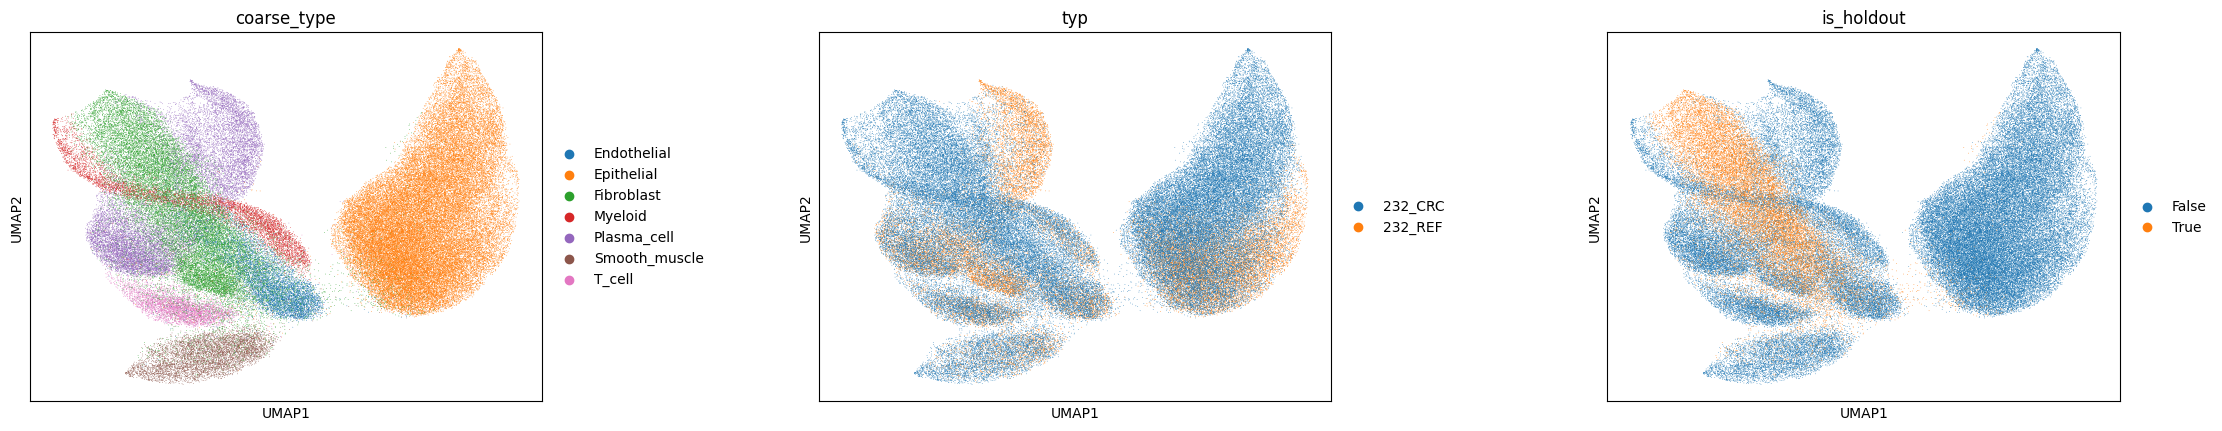

In [23]:
sc.pl.umap(adata, color=[labels_key, domains_key, 'is_holdout'], wspace=0.4)

In [24]:
sc.pp.neighbors(adata, use_rep='cellina_spatial')
sc.tl.umap(adata)

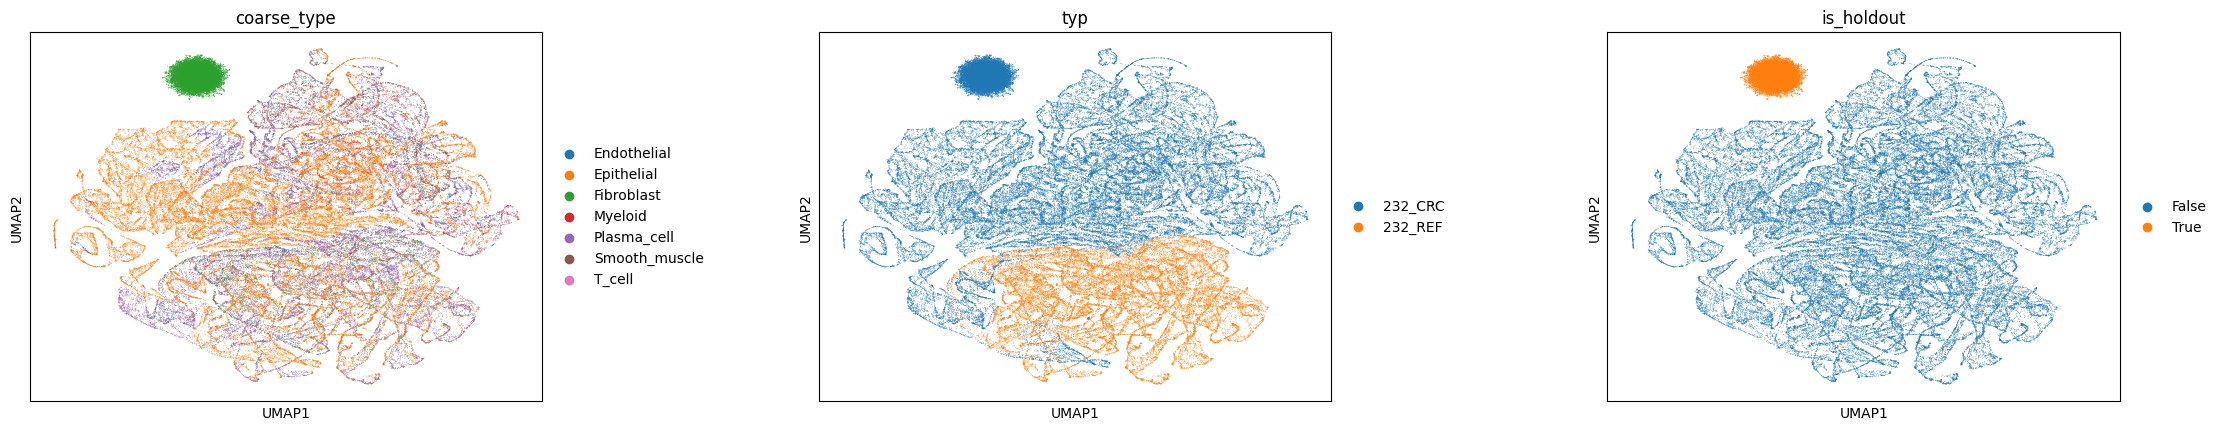

In [25]:
sc.pl.umap(adata, color=[labels_key, domains_key, 'is_holdout'], wspace=0.4)

## 4. Counterfactuals

A tissue-graph counterfactual asks: *what would a cell express if its neighbourhood context changed, while its intrinsic identity stayed fixed?* The spatial graph $\mathcal{G}$ has two mutable parts — its **edges** (neighbourhood topology) and its **node features** (neighbour expression) — giving two perturbation types, both applied **post-training**:

- **Edge perturbation** modifies a cell's neighbours $\mathcal{N}(v)$.
- **Node perturbation** modifies the gene features $\{x_u : u \in \mathcal{N}(v)\}$ of fixed neighbours.

In both cases we evaluate on the **held-out cancer Fibroblasts**: cells whose true tumour-context expression the model never saw during training. We compare the *observed* healthy→cancer log-fold change (ground truth) against the *predicted* one (counterfactual).

### 4.1 Edge perturbation

**Edge perturbation** (Definition 1) intervenes on a cell's neighbourhood, $\mathcal{N}(v) := \mathcal{N}'$ — neighbours may be added, removed, or replaced.

Here we evaluate it as a **domain edge-rewiring**. Let $\mathcal{I}_y$ be the focal cells of type $y$ (Fibroblast) in the **source** domain (healthy, `REF`), and $\mathcal{A}_y$ the cells of the same type in the **target** domain (cancer, `CRC`). For each focal cell $v \in \mathcal{I}_y$ we draw one anchor $a \in \mathcal{A}_y$ and set $\mathcal{N}(v) := \mathcal{N}(a) \setminus y$ — the anchor's own observed neighbourhood, with every type-$y$ cell removed, which keeps the counterfactual conservative. Since the cancer Fibroblasts were held out of the training graph, this tests whether `Cellina` can predict how a healthy Fibroblast would shift if placed in a tumour microenvironment it never saw.

First, we get indices of *control* and *target* cells. *Control* cells are Fibroblasts that we have seen during training (in the healthy region),
and *target* cells are Fibroblasts in the cancer region that were held-out during training.
We call these *target* cells because we want to apply in-silico perturbations to *control* cells to look like *target* cells.

In [26]:
is_control_region = adata.obs[domains_key].str.contains('REF')
mask_control = is_control_region & is_holdout_ct
idx_control = np.where(mask_control.values)[0]

mask_target = is_tumor_region & is_holdout_ct
idx_target = np.where(mask_target.values)[0]

`get_counterfactual_expression` transplants a real neighbourhood onto each control cell and decodes the resulting expression. With `anchor_donors=True`, every cell in `indices` is paired with one random *anchor* from `neighbour_indices` — here `idx_target`, the held-out Fibroblasts of the cancer region — and takes over that anchor's own observed neighbourhood. Those neighbourhoods are rebuilt from `spatial_connectivities_orig`, the **unmasked** graph, because the anchors were masked out of the training graph and their stored `spatial_x` rows are all-zero. Every cell of the held-out type is passed as `exclude_indices`, so no held-out expression ever enters the counterfactual features. Anchors whose neighbours are all held-out-type cells (homotypic) are skipped with a warning.

`layer` must match the representation the training spatial features were built from — here `'lognorm'` (log1p CP10K), since `adata.X` holds raw counts at this point. The `Cellina-GAT` tutorial uses the same call; there the rewired neighbourhood is aggregated by the GAT on the fly rather than into a precomputed $\varphi(v)$.

In [27]:
counterfactual_counts = model.get_counterfactual_expression(
    indices=idx_control,
    neighbour_indices=idx_target,                     # anchor cells
    anchor_donors=True,
    connectivity_key="spatial_connectivities_orig",   # unmasked graph: the anchors were masked for training
    exclude_indices=np.where(is_holdout_ct.values)[0],
    layer="lognorm",                                  # spatial_x was built from log1p(CP10K); adata.X is counts
    batch_size=2048,
    seed=0,
)

INFO     AnnData object appears to be a copy. Attempting to transfer setup.                                        


/data/a330d/miniforge3/envs/cellina-graph/lib/python3.10/site-packages/scvi/data/fields/_layer_field.py:115: UserWarning: Training will be faster when sparse matrix is formatted as CSR. It is safe to cast before model initialization.
  _verify_and_correct_data_format(adata, self.attr_name, self.attr_key)


In [28]:
def _normalize_counts(x, eps=1e-8, scale=1e4):
    return x / (x.sum(axis=1, keepdims=True) + eps) * scale

def safe_log2_fold_change(a, b, eps=1e-6):
    """
    Compute log2((a + eps) / (b + eps)) elementwise.
    Use this instead of log2(a - b). eps should be set relative to normalized scale.
    """
    a = np.asarray(a)
    b = np.asarray(b)
    return np.log2((a + eps) / (b + eps))

def get_lfc(control, target, counterfactual, normalize_counts=True, n_deg=200):
    if normalize_counts:
        control = _normalize_counts(control)
        target = _normalize_counts(target)
        counterfactual = _normalize_counts(counterfactual)

    mean_control = np.nanmean(control, axis=0)
    mean_target = np.nanmean(target, axis=0)
    mean_cf = np.nanmean(counterfactual, axis=0)

    # compute log2 fold changes
    gt_vec = safe_log2_fold_change(mean_target, mean_control)
    cf_vec = safe_log2_fold_change(mean_cf, mean_control)

    deg_scores = np.abs(gt_vec)
    top_features = np.argsort(-deg_scores)[:n_deg]

    return gt_vec, cf_vec, top_features

Finally, we compare the ground-truth log-fold change (healthy vs. cancer Fibroblasts) against the counterfactual one (healthy vs. edge-perturbed Fibroblasts). We highlight the top differentially-expressed genes (largest $|$observed logFC$|$) and report Pearson's $r$ over them.

In [29]:
control = np.array(adata.layers['counts'][mask_control.values, :].todense())
target = np.array(adata.layers['counts'][mask_target.values, :].todense())
counterfactual = counterfactual_counts

true_lfc, pred_lfc, deg = get_lfc(control=control, target=target, counterfactual=counterfactual, n_deg=50)

In [30]:
pearson, _ = pearsonr(true_lfc[deg], pred_lfc[deg])

If the autoencoder has learned a useful spatial representation, swapping only the neighbours should turn healthy Fibroblasts into cancer-like Fibroblasts. The top gene changes would then follow the identity line, and you can compare Pearson's $r$ with the VAE tutorial.

In [31]:
from adjustText import adjust_text


def plot_lfc(true_lfc, pred_lfc, deg, gene_names, holdout_ct, pearson):
    """Scatter of observed vs. predicted logFC, highlighting the top DE genes.

    Top genes are coloured by the direction of the *observed* change and their
    names are repelled with adjustText so the labels stay legible.
    """
    fig, ax = plt.subplots(figsize=(6, 5.5))

    deg = np.asarray(deg)
    non_deg = np.setdiff1d(np.arange(len(true_lfc)), deg)

    # background (non-DE) genes
    ax.scatter(true_lfc[non_deg], pred_lfc[non_deg],
               alpha=0.25, s=8, color="lightgray", linewidths=0, rasterized=True)

    # top DE genes, coloured by the direction of the observed change
    up = deg[true_lfc[deg] >= 0]
    down = deg[true_lfc[deg] < 0]
    ax.scatter(true_lfc[up], pred_lfc[up], s=45, color="#d62728",
               edgecolor="white", linewidths=0.5, zorder=3, label="up in cancer")
    ax.scatter(true_lfc[down], pred_lfc[down], s=45, color="#1f77b4",
               edgecolor="white", linewidths=0.5, zorder=3, label="down in cancer")

    # repelled gene labels
    texts = [ax.text(true_lfc[i], pred_lfc[i], gene_names[i], fontsize=8) for i in deg]
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="0.6", lw=0.5))

    # identity line
    lo = float(min(true_lfc.min(), pred_lfc.min()))
    hi = float(max(true_lfc.max(), pred_lfc.max()))
    pad = 0.05 * (hi - lo)
    lims = [lo - pad, hi + pad]
    ax.plot(lims, lims, "k--", lw=1, alpha=0.6, zorder=1)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_aspect("equal")

    ax.set_xlabel("Observed logFC  (control → cancer)")
    ax.set_ylabel("Predicted logFC  (counterfactual)")
    ax.set_title(f"{holdout_ct}: observed vs. predicted logFC   (Pearson r = {pearson:.2f})")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    fig.tight_layout()
    plt.show()

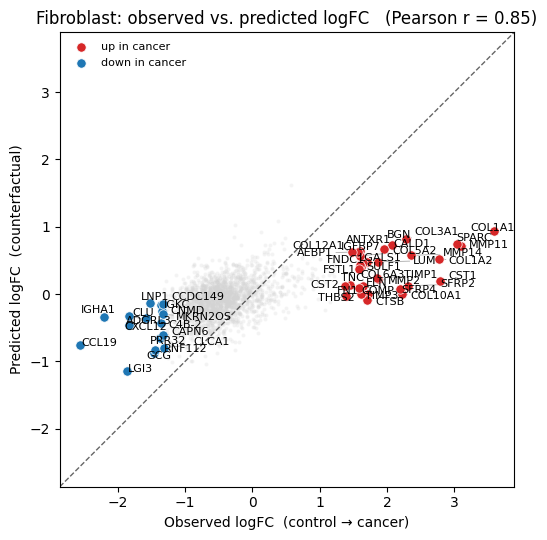

In [32]:
gene_names = np.array(adata.var_names)

plot_lfc(true_lfc, pred_lfc, deg, gene_names, holdout_ct, pearson)

### 4.2 Node perturbation

**Node perturbation** (Definition 2) keeps the graph topology fixed but edits the neighbours' feature vectors. For a target gene set $\mathcal{S}$,

$$x_{u,g}^{\mathrm{cf}} = \begin{cases} T_g(x_{u,g}) & g \in \mathcal{S} \\ x_{u,g} & g \notin \mathcal{S}. \end{cases}$$

The transformation $T_g$ is arbitrary (knockout, overexpression, an additive shift, …); restricting it to a gene set $\mathcal{S}$ is biologically motivated, since genes act in co-regulated programs (a pathway or regulon). Biologically, this mimics an intervention — e.g. a CRISPR perturbation — applied to the neighbouring cells. Here we instantiate $T_g$ as the **observed healthy→cancer log-fold change** of the top-$n$ genes, estimated **per cell type** by pseudobulk. Crucially, the held-out Fibroblast population is shifted by the *global* (cell-type-averaged) change rather than its own, so the model never sees the true Fibroblast perturbation it is asked to predict.

In [ ]:
n_pert_genes = 200 # NOTE: we assume that a smaller number would be approriate for targeted perturbations, while for our cancer case we want to capture a broader phenotypic shift with more genes
control_domain = '232_REF'
target_domain = '232_CRC'

Here we define helper functions to compute the perturbation logFC (global and cell-type-specific) from pseudobulk profiles, using `decoupler` {cite:p}`badia2022decoupler`.

In [ ]:
import pandas as pd
import scipy.sparse as sp
import decoupler as dc

def get_perturbation_logfc(adata, control_domain, holdout_domain, labels_key, domains_key):
    # Cell-type-specific
    pdata_ct = dc.pp.pseudobulk(
        adata=adata, sample_col=domains_key, groups_col=labels_key, mode='sum', layer='counts'
    )
    sc.pp.normalize_total(pdata_ct, target_sum=1e4)
    sc.pp.log1p(pdata_ct)

    cell_types_with_both = [
        ct for ct in pdata_ct.obs[labels_key].unique()
        if ((pdata_ct.obs[domains_key] == control_domain) & (pdata_ct.obs[labels_key] == ct)).any()
        and ((pdata_ct.obs[domains_key] == holdout_domain) & (pdata_ct.obs[labels_key] == ct)).any()
    ]

    _ct_rows = []
    for _ct in cell_types_with_both:
        _crc_ct = pdata_ct[(pdata_ct.obs[domains_key] == holdout_domain) & (pdata_ct.obs[labels_key] == _ct)].X
        _ref_ct = pdata_ct[(pdata_ct.obs[domains_key] == control_domain) & (pdata_ct.obs[labels_key] == _ct)].X
        _crc_m  = np.asarray(_crc_ct.mean(axis=0)).flatten() if sp.issparse(_crc_ct) else _crc_ct.mean(axis=0).flatten()
        _ref_m  = np.asarray(_ref_ct.mean(axis=0)).flatten() if sp.issparse(_ref_ct) else _ref_ct.mean(axis=0).flatten()
        _ct_rows.append(pd.Series(_crc_m - _ref_m, index=pdata_ct.var_names, name=_ct))
    domain_logfc_df = pd.concat(_ct_rows, axis=1).T

    return domain_logfc_df


def get_global_perturbation_logfc(adata, control_domain, holdout_domain, labels_key, domains_key, holdout_ct):
    adata_sub = adata[adata.obs[labels_key]!=holdout_ct]
    pdata_global = dc.pp.pseudobulk(
        adata=adata_sub, sample_col=domains_key, groups_col=None, mode='sum', layer='counts'
    )
    sc.pp.normalize_total(pdata_global, target_sum=1e4)
    sc.pp.log1p(pdata_global)

    _holdout_X    = pdata_global[pdata_global.obs[domains_key] == holdout_domain].X
    _control_X    = pdata_global[pdata_global.obs[domains_key] == control_domain].X
    _holdout_mean = np.asarray(_holdout_X.mean(axis=0)).flatten() if sp.issparse(_holdout_X) else _holdout_X.mean(axis=0).flatten()
    _control_mean = np.asarray(_control_X.mean(axis=0)).flatten() if sp.issparse(_control_X) else _control_X.mean(axis=0).flatten()

    return pd.Series(_holdout_mean - _control_mean, index=pdata_global.var_names)

In [ ]:
# Cell-type-specific perturbation
domain_logfc_df = get_perturbation_logfc(adata, control_domain, target_domain, labels_key, domains_key)
global_logfc_series = get_global_perturbation_logfc(adata, control_domain, target_domain, labels_key, domains_key, holdout_ct)
domain_logfc_df.loc[holdout_ct, global_logfc_series.index] = global_logfc_series # NOTE: set the holdout celltype's perturbation to the global perturbation - ct

logfc_series_dict = {}
for ct in domain_logfc_df.index:
    s = domain_logfc_df.loc[ct]
    top_g = s.abs().nlargest(n_pert_genes).index.tolist()
    logfc_series_dict[ct] = s[top_g]

For base `Cellina`, the shift is applied additively in log-space on the **aggregated** neighbour features (`make_neighbor_perturbation`, `add_shift=True`), then re-aggregated into the spatial features $\varphi(v)$ before inference. (For the `Cellina-GAT` variant, the shift is instead applied to each neighbour cell individually via `make_perturbed_expression` and a `cf_layer`, and aggregated by the GAT on the fly.)

In [ ]:
make_neighbor_perturbation(
        adata,
        perturbations=logfc_series_dict,
        groupby=labels_key,
        obsm_key_out='spatial_x_cf',
        base=np.e,
        renormalize=True,
        add_shift=True,
        # perturb the normalized representation (adata.X stays raw counts)
        layer='lognorm',
)
pert_expr = model.get_perturbed_expression(
    adata=adata, indices=idx_control, spatial_obsm_key='spatial_x_cf',
    batch_size=2048, library_size=1e4,
)

In [ ]:
control = np.array(adata.layers['counts'][mask_control.values, :].todense())
target = np.array(adata.layers['counts'][mask_target.values, :].todense())
counterfactual = pert_expr

true_lfc, pred_lfc, deg = get_lfc(control=control, target=target, counterfactual=counterfactual, n_deg=20)

In [ ]:
pearson, _ = pearsonr(true_lfc[deg], pred_lfc[deg])

As before, we compare the predicted effect of the neighbouring gene modifications on the held-out Fibroblast population with the observed change.

In [ ]:
plot_lfc(true_lfc, pred_lfc, deg, gene_names, holdout_ct, pearson)

## References

```{bibliography}
:filter: docname in docnames
```